# Experiments to close the remaining gaps

Two experiments, both on NYUv2.

| Exp. | Change vs `nyu_partial_ft` (B) | Question | Folder |
|---|---|---|---|
| E1 | **8** trainable ViT blocks (5–12) instead of 4, same LR rule (1e-5 · 0.9^k), critic still on (as B) | B beat A by +4.5 mIoU and −0.035 m RMSE on NYU. Does more backbone adaptation help NYU depth further? | `ckpt/exp/`, `results/exp/` |
| E2 | critic **off** (`use_critic=False`), everything else as B | Does the WGAN-GP critic help at all? In notebook 02 it contributes ≤ 1.5 % of the loss ('The critic (WGAN-GP), ported from SwinMTL') | `ckpt/nocritic/`, `results/nocritic/` |

## Setup

***NOTE:*** The DINOv2 and DPT code is used straight from the local repositories `./dinov2` and `./DPT`.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "experiments":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

In [2]:
from mtl_train import *
from repro_common import PAPER   # the papers' reference numbers, defined once (checked against the PDFs)

configure()
print(f"Device: {device}, GPU: {torch.cuda.get_device_name(0) if device.type == 'cuda' else 'none'}")


Device: cuda, GPU: NVIDIA RTX A4000


## E1: NYUv2, 8 trainable blocks

In [3]:
configure(ckpt_root=ROOT / "ckpt" / "exp", results_root=ROOT / "results" / "exp")
CFG["variants"]["partial_ft8"] = dict(CFG["variants"]["partial_ft"], n_trainable_blocks=8)

hist_e1 = train_run("nyu", "partial_ft8")

nyu_partial_ft8: already trained


## E2: NYUv2, variant B without the critic

In [4]:
configure(use_critic=False, ckpt_root=ROOT / "ckpt" / "nocritic", results_root=ROOT / "results" / "nocritic")

hist_e2 = train_run("nyu", "partial_ft")

nyu_partial_ft: already trained


## Evaluation and comparison
Every run is scored with notebook 03's NYU protocols: single pass, flip and sliding window (TTA), each on the full 654-image test set. The baseline B is read from `results/eval/nyu_partial_ft.json`, and the paper references are SwinMTL Tab. III, DINOv2 Tab. 11 (DPT) and DPT Tab. 2. Results are cached in `<results_root>/eval/`.

In [5]:
EXPERIMENTS = [
    # label, configure overrides, variant
    ("B (main run, 4 blocks)", dict(), "partial_ft"),
    ("E1: 8 trainable blocks", dict(ckpt_root=ROOT / "ckpt" / "exp", results_root=ROOT / "results" / "exp"), "partial_ft8"),
    ("E2: B without critic", dict(use_critic=False, ckpt_root=ROOT / "ckpt" / "nocritic", results_root=ROOT / "results" / "nocritic"), "partial_ft"),
]


def eval_experiment(overrides: dict, variant: str) -> Optional[dict]:
    configure(**overrides)
    CFG["variants"]["partial_ft8"] = dict(CFG["variants"]["partial_ft"], n_trainable_blocks=8)
    out_path = CFG["results_root"] / "eval" / f"{run_name('nyu', variant)}.json"
    cached = load_json(out_path) if out_path.exists() else None
    if cached and "nyu_depth_slide" in cached:
        return cached
    if not (CFG["ckpt_root"] / run_name("nyu", variant) / "final.pt").exists():
        print(f"{variant} in {CFG['ckpt_root']}: not trained")
        return None
    model = load_trained("nyu", variant)
    results = eval_nyu(model, slide=True)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    save_json(results, out_path)
    del model
    torch.cuda.empty_cache()
    return results


rows = [
    {"model": "SwinMTL (Tab. III)", "RMSE": PAPER["swinmtl_tab3"]["SwinMTL"][0], "mIoU (paper: as reported; ours: standard)": PAPER["swinmtl_tab3"]["SwinMTL"][1]},
    {"model": "DINOv2 ViT-S/14 + DPT (Tab. 11; ≈ 24k training frames)", "RMSE": PAPER["dinov2_tab11_vits14"]["nyu"][2]},
    {"model": "DPT-Hybrid (Tab. 2; pretrained on ≈ 1.4 M images (MIX 6), fine-tuned on NYUv2)", "RMSE": PAPER["dpt_tab2"]["DPT-Hybrid"]["rmse"], "AbsRel": PAPER["dpt_tab2"]["DPT-Hybrid"]["abs_rel"], "δ1": PAPER["dpt_tab2"]["DPT-Hybrid"]["d1"]},
]
EXP_RESULTS = {}
for label, overrides, variant in EXPERIMENTS:
    results = eval_experiment(overrides, variant)
    EXP_RESULTS[label] = results
    if not results:
        continue
    for key, seg_key, suffix in [("nyu_depth", "nyu_seg", ""), ("nyu_depth_flip", None, " +flip (TTA)"), ("nyu_depth_slide", "nyu_seg_slide", " +slide (TTA)")]:
        rows.append({
            "model": label + suffix,
            "RMSE": results[key]["rmse"], "AbsRel": results[key]["abs_rel"], "δ1": results[key]["d1"],
            "mIoU (paper: as reported; ours: standard)": results[seg_key]["mIoU"] if seg_key else None,
            "mIoU (ours: SwinMTL per-image)": results[seg_key.replace("nyu_seg", "nyu_seg_swinmtl")]["mIoU"] if seg_key else None,
        })

configure()
exp_table = pd.DataFrame(rows).set_index("model")
exp_table.to_csv(ROOT / "results" / "compare" / "experiments_nyu.csv")
display(exp_table.style.format(lambda v: "—" if pd.isna(v) else f"{v:.4f}" if v < 2 else f"{v:.2f}"))

,RMSE,mIoU (paper: as reported; ours: standard),AbsRel,δ1,mIoU (ours: SwinMTL per-image)
model,,,,,
SwinMTL (Tab. III),0.5179,58.14,—,—,—
DINOv2 ViT-S/14 + DPT (Tab. 11; ≈ 24k training frames),0.3560,—,—,—,—
"DPT-Hybrid (Tab. 2; pretrained on ≈ 1.4 M images (MIX 6), fine-tuned on NYUv2)",0.3570,—,0.1100,0.9040,—
"B (main run, 4 blocks)",0.4329,57.27,0.1247,0.8570,58.20
"B (main run, 4 blocks) +flip (TTA)",0.4255,—,0.1224,0.8619,—
"B (main run, 4 blocks) +slide (TTA)",0.4208,59.00,0.1197,0.8657,60.56
E1: 8 trainable blocks,0.4242,57.79,0.1210,0.8623,58.39
E1: 8 trainable blocks +flip (TTA),0.4177,—,0.1191,0.8668,—
E1: 8 trainable blocks +slide (TTA),0.4140,59.34,0.1166,0.8714,60.91


### Training curves of the experiments vs B

The "quick val" curves use only the first 100 test images and are for monitoring training. They are noisy (e.g. at 20k the quick mIoU of B is above E1, the reverse of the full evaluation), so every conclusion uses the full 654-image evaluation above.

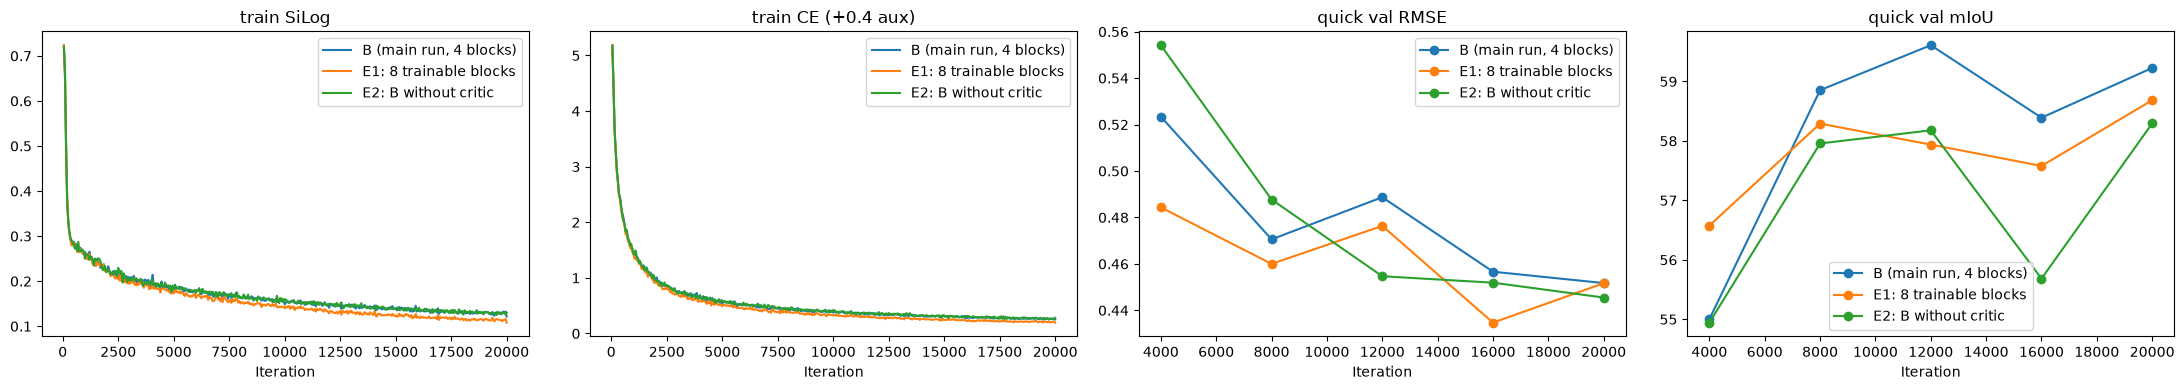

In [6]:
fig, axs = plt.subplots(1, 4)
fig.set_size_inches(22, 4)
for label, overrides, variant in EXPERIMENTS:
    results_root = overrides.get("results_root", ROOT / "results")
    history = load_json(results_root / "train" / f"{run_name('nyu', variant)}.json")
    if not history:
        continue
    axs[0].plot(history["iter"], history["depth"], label=label)
    axs[1].plot(history["iter"], history["seg"], label=label)
    iters = [v["iter"] for v in history["val"]]
    axs[2].plot(iters, [v["rmse"] for v in history["val"]], "o-", label=label)
    axs[3].plot(iters, [v["mIoU"] for v in history["val"]], "o-", label=label)
for ax, title in zip(axs, ["train SiLog", "train CE (+0.4 aux)", "quick val RMSE", "quick val mIoU"]):
    ax.set_title(title)
    ax.set_xlabel("Iteration")
    ax.legend()
plt.tight_layout()
fig.savefig(ROOT / "results" / "compare" / "experiments_nyu_curves.png", dpi=120)
plt.show()